# Day 09 — Train so sánh: dữ liệu **gốc** vs dữ liệu **sau pipeline**

Thí nghiệm công bằng: cùng model khởi tạo `yolo26n.pt`, cùng siêu tham số, cùng seed, cùng tập val (`data/gold_val`, 40 ảnh) và cùng tập **test** (`data/test`, 100 ảnh, nhãn người).
Chỉ khác **dữ liệu train**:

| biến thể | ảnh | nhãn |
|---|---|---|
| `raw` | toàn bộ `data/raw/images` | nhãn gốc, **không sửa gì** |
| `clean` | ảnh trong `manifest.json` của bạn | nhãn sau pipeline (`submission/export/clean_v1`) |
| `oracle` (tuỳ chọn) | như `clean` | nhãn người — chặn trên |

[![Mở trên Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<tài-khoản-của-bạn>/<tên-repo>/blob/main/notebooks/day09_train_compare.ipynb) ← thay `<...>` bằng repo của bạn (public), hoặc: Colab → File → Open notebook → tab GitHub → dán URL repo.

**Hết quota GPU / không vào được Colab?** Kaggle Notebook (GPU P100/T4 miễn phí, bật Internet) chạy được y hệt; hoặc chạy cục bộ rút gọn: `python scripts/train_compare.py --variants raw clean --seeds 0 --epochs 15 --imgsz 416 --device cpu` (chậm nhưng khả thi; ghi rõ cấu hình rút gọn trong REPORT.md).

**Trước khi chạy:** Runtime → Change runtime type → **T4 GPU**. Bạn đã `git push` thư mục `submission/export/clean_v1/` chưa?

In [9]:
# 1. Cấu hình — SỬA REPO_URL thành repo CỦA BẠN (public)
REPO_URL = "https://github.com/khoivancw/K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab.git"
SEEDS = [0, 1]          # 2 seed để biết độ nhiễu
EPOCHS = 20
VARIANTS = ["raw", "clean"]   # thêm "oracle" nếu muốn chặn trên
V_ARG = " ".join(VARIANTS); S_ARG = " ".join(map(str, SEEDS))

In [10]:
# 2. GPU + lấy code
!nvidia-smi -L
import os, subprocess
repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
if not os.path.exists(repo):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
%cd {repo}
!git log --oneline | head -3

GPU 0: NVIDIA GeForce RTX 4050 Laptop GPU (UUID: GPU-f28606c8-f9e3-9ee4-e6fc-1653614e2c3e)


CalledProcessError: Command '['git', 'clone', '--depth', '1', 'https://github.com/khoivancw/K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab.git']' returned non-zero exit status 128.

In [ ]:
# 3. Cài đặt (Colab đã có torch)
!pip install -q "ultralytics==8.4.214" imagehash pyyaml matplotlib
import ultralytics; print("ultralytics", ultralytics.__version__)


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


ultralytics 8.4.214


In [ ]:
!git pull --ff-only origin main
!git rev-parse --short HEAD

Updating f539663..18b0234
Fast-forward
 README.md                                      |   2 +-
 configs/pipeline.yaml                          |   4 +-
 pipeline/checks/label_format.py                |  98 +++-
 pipeline/checks/second_opinion.py              | 118 ++++-
 pipeline/steps/autofix.py                      | 133 +++++-
 pipeline/steps/gate.py                         |  43 +-
 submission/REPORT.md                           |  99 ++++-
 submission/calibration/calibration.json        | 589 +++++++++++++++++++++++++
 submission/calibration/calibration_report.md   |  46 ++
 submission/export/clean_v1/data.yaml           |   6 +
 submission/export/clean_v1/labels/img_0001.txt |   3 +
 submission/export/clean_v1/labels/img_0002.txt |   3 +
 submission/export/clean_v1/labels/img_0003.txt |   1 +
 submission/export/clean_v1/labels/img_0004.txt |   3 +
 submission/export/clean_v1/labels/img_0005.txt |   5 +
 submission/export/clean_v1/labels/img_0006.txt |   1 +
 submission/export/cl

From https://github.com/khoivancw/K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab
 * branch            main       -> FETCH_HEAD
   f539663..18b0234  main       -> origin/main


18b0234


In [11]:
# 4. Kiểm tra export của bạn
import json, pathlib
m = pathlib.Path("submission/export/clean_v1/manifest.json")
assert m.exists(), "Chưa có submission/export/clean_v1/manifest.json — chạy `make run` ở máy bạn rồi commit + push."
man = json.loads(m.read_text())
print("quyết định pipeline:", man["decision"]["decision"], "|", "; ".join(man["decision"]["reasons"]))
print("số ảnh train của clean:", man["n_images"], "| số ảnh raw:", len(list(pathlib.Path("data/raw/images").iterdir())))

quyết định pipeline: Hold | Tá»‰ lá»‡ áº£nh cÃ³ cáº£nh bÃ¡o 17.62% >= ngÆ°á»¡ng 10.00% (34/193 áº£nh)
số ảnh train của clean: 193 | số ảnh raw: 224


In [12]:
# 5. Dựng 2 bộ dữ liệu và xem thống kê (số ảnh, số box theo lớp)
import collections, pathlib, subprocess, sys
for v in VARIANTS:
    exp = "submission/export/clean_auto" if v == "auto" else "submission/export/clean_v1"
    subprocess.run([sys.executable, "scripts/materialize_dataset.py", "--variant", v, "--out", f"work/train/{v}", "--export", exp], check=True)
    cnt = collections.Counter()
    for f in pathlib.Path(f"work/train/{v}/train/labels").glob("*.txt"):
        for ln in f.read_text().splitlines():
            if ln.split(): cnt[ln.split()[0]] += 1
    print(v, "box theo token lớp:", dict(sorted(cnt.items())))

raw box theo token lớp: {'-1': 2, '0': 122, '1': 537, '2': 32, '3': 35, '4': 2, '7': 1, '93': 1}
clean box theo token lớp: {'0': 101, '1': 550, '2': 41, '3': 31}


In [13]:
# 6. TRAIN (≈ 3–5 phút/lần trên T4; 2 biến thể × 2 seed ≈ 15–20 phút). Ultralytics sẽ in cảnh báo ảnh/nhãn hỏng của `raw`: ĐỌC chúng.
!python scripts/train_compare.py --variants {V_ARG} --seeds {S_ARG} --epochs {EPOCHS}

raw: 224 ảnh train, 218 file nhãn -> D:\AI_VinUni\lv2\02_Labs_Thuc_Hanh\K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab\notebooks\K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab\work\train\raw

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.214  Python-3.14.2 torch-2.15.0+cpu CPU (13th Gen Intel Core i5-13500HX)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\AI_VinUni\lv2\02_Labs_Thuc_Hanh\K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab\notebooks\K5-L23-Day09-03290-LeVanKhoi-AutoQC-Pipeline-Lab\work\train\raw\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0,

| biến thể | #ảnh train | số seed | map50 (TB ± độ lệch) | map50_95 (TB ± độ lệch) | precision (TB ± độ lệch) | recall (TB ± độ lệch) |
|---|---|---|---|---|---|---|
| raw | 224 | 2 | 0.713 ± 0.011 | 0.508 ± 0.018 | 0.714 ± 0.046 | 0.666 ± 0.040 |
| clean | 193 | 2 | 0.727 ± 0.012 | 0.502 ± 0.017 | 0.813 ± 0.029 | 0.609 ± 0.018 |

Chênh mAP50 (clean − raw) = **+0.015**.
đã ghi comparison.png


| biáº¿n thá»ƒ | #áº£nh train | sá»‘ seed | map50 (TB Â± Ä‘á»™ lá»‡ch) | map50_95 (TB Â± Ä‘á»™ lá»‡ch) | precision (TB Â± Ä‘á»™ lá»‡ch) | recall (TB Â± Ä‘á»™ lá»‡ch) |
|---|---|---|---|---|---|---|
| raw | 224 | 2 | 0.713 Â± 0.011 | 0.508 Â± 0.018 | 0.714 Â± 0.046 | 0.666 Â± 0.040 |
| clean | 193 | 2 | 0.727 Â± 0.012 | 0.502 Â± 0.017 | 0.813 Â± 0.029 | 0.609 Â± 0.018 |

ChÃªnh mAP50 (clean âˆ’ raw) = **+0.015**.


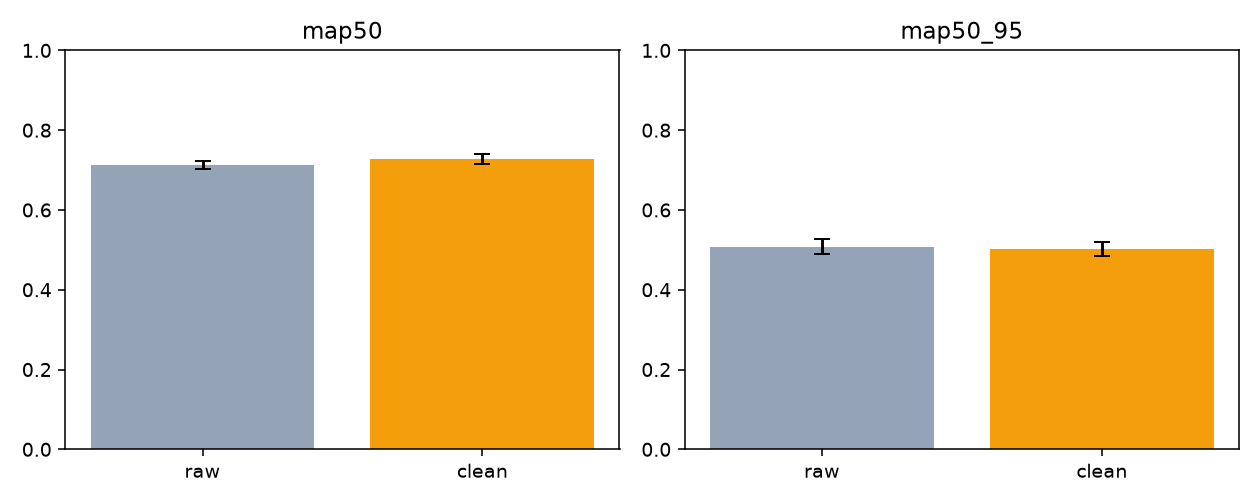

In [14]:
# 7. Tổng hợp
!python scripts/summarize_results.py
from IPython.display import Image, display, Markdown
display(Markdown(open("submission/results/comparison.md").read()))
display(Image("submission/results/comparison.png"))

In [18]:
%pip install pandas

  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
# 8. AP theo lớp (xem lớp nào được lợi / bị hại)
import json, glob, pandas as pd
rows = []
for p in sorted(glob.glob("submission/results/*_seed*.json")):
    d = json.load(open(p)); rows.append({"variant": d["variant"], "seed": d["seed"], "train_images": d["train_images"], "mAP50": d["map50"], **{f"AP50_{k}": v for k, v in d["ap50_per_class"].items()}})
pd.DataFrame(rows)

,variant,seed,train_images,mAP50,AP50_car,AP50_person,AP50_truck,AP50_bus
0,clean,0,193,0.7188,0.7510,0.8140,0.5923,0.7179
1,clean,1,193,0.7359,0.8048,0.8214,0.6290,0.6885
2,raw,0,224,0.7049,0.7652,0.8180,0.5762,0.6602
3,raw,1,224,0.7204,0.7343,0.8228,0.6188,0.7057


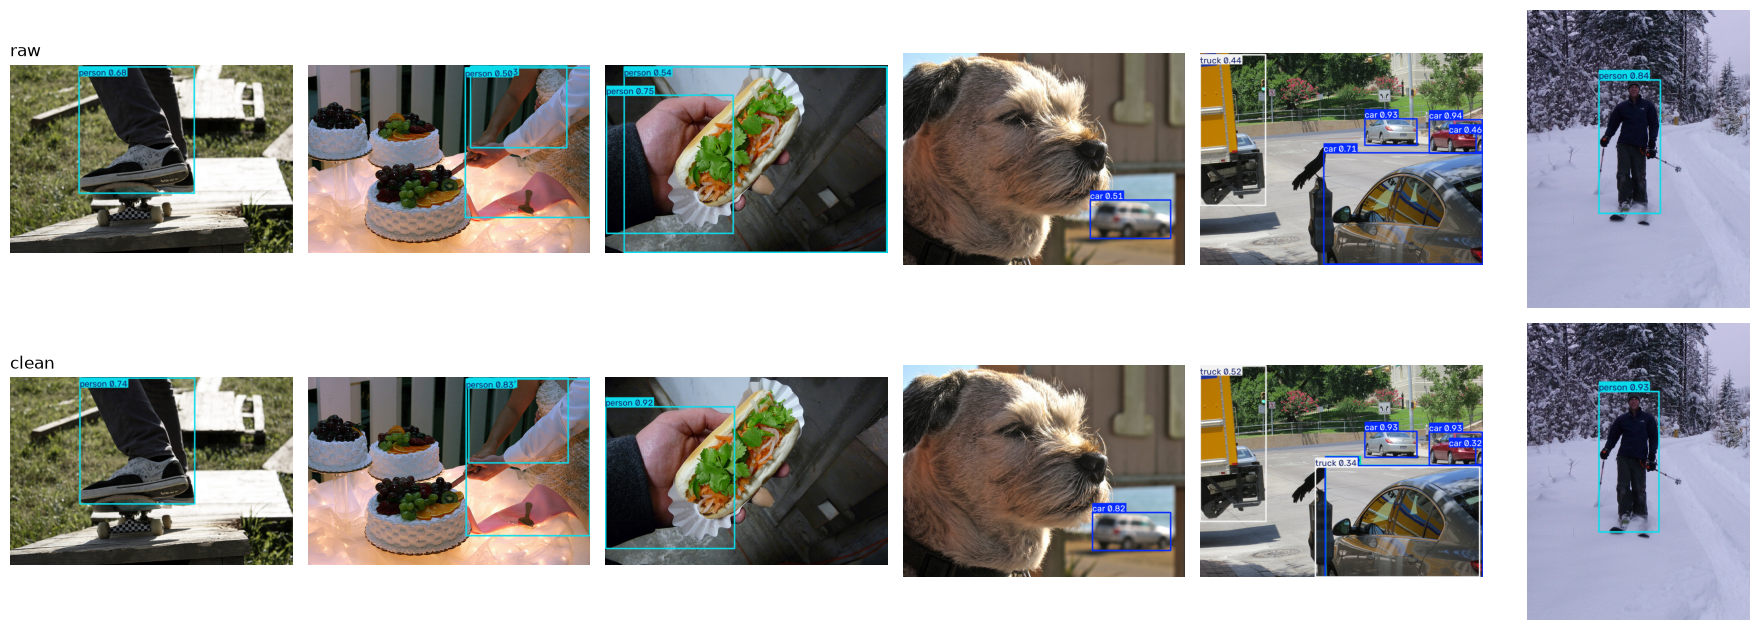

In [20]:
# 9. Ví dụ dự đoán trên 6 ảnh test của hai mô hình (seed 0) — nhìn bằng mắt, đừng chỉ tin con số
import matplotlib.pyplot as plt
from ultralytics import YOLO
from PIL import Image as PI
imgs = sorted(glob.glob("data/test/images/*.jpg"))[:6]
fig, ax = plt.subplots(len(VARIANTS), 6, figsize=(18, 3.2 * len(VARIANTS)))
for r, v in enumerate(VARIANTS):
    w = YOLO(f"work/train/runs/{v}_seed0/weights/best.pt")
    for c, im in enumerate(imgs):
        ax[r][c].imshow(w.predict(im, conf=0.25, verbose=False)[0].plot()[..., ::-1]); ax[r][c].axis("off")
    ax[r][0].set_title(v, loc="left")
plt.tight_layout()

In [21]:
# 10. Lưu kết quả: tải về rồi commit vào submission/results/ (KHÔNG sửa tay các file này)
!zip -qr results.zip submission/results
try:
    from google.colab import files; files.download("results.zip")
except Exception as e:
    print("Không phải Colab:", e)

Không phải Colab: No module named 'google'


## Việc của bạn
Viết `submission/results/ANALYSIS.md` (mẫu có sẵn trong repo). Câu hỏi để bạn bắt đầu:
1. Chênh `mAP50(clean) − mAP50(raw)` so với độ lệch chuẩn giữa các seed? Kết luận được đến đâu với 2 seed?
2. `raw` thật sự train trên bao nhiêu ảnh? (đọc cảnh báo Ultralytics ở bước 6: nó tự bỏ ảnh có nhãn hỏng / box tràn).
3. `raw` có ảnh trùng với tập test không? Nếu có, điểm của `raw` bị thổi phồng bao nhiêu? Làm sao kiểm? (gợi ý: pipeline của bạn đã phát hiện `LEAK_TEST`)
4. Lớp nào (car/person/truck/bus) được lợi nhất? Giải thích bằng loại lỗi nhãn trong `02_error_list_v1`.
5. `clean` còn lỗi gì? (hàng đợi người duyệt có vượt ngân sách không?) Đây là chặn trên của "dữ liệu sạch" hay chưa?